In [14]:
# ==========================================
# UPLOAD DATASET EXCEL
# ==========================================

from google.colab import files

uploaded = files.upload()

Saving 21-24.-jumlah-usaha_industri-sektor-pariwisata-rev.261111.xlsx to 21-24.-jumlah-usaha_industri-sektor-pariwisata-rev.261111 (1).xlsx


In [15]:
# ==========================================
# MEMBACA DATASET EXCEL
# ==========================================

import pandas as pd
import os

nama_file = list(uploaded.keys())[0]

df = pd.read_excel(nama_file)

print("Dataset berhasil dibaca!")
print("Jumlah baris dan kolom:", df.shape)

display(df.head())

Dataset berhasil dibaca!
Jumlah baris dan kolom: (308, 7)


,tahun,2_digit_kbli,sektor,kbli,kelompok_usaha,resiko,jumlah_usaha
0,2021,49,Jasa Transportasi Wisata,49425,Angkutan Darat Wisata,MR,1214
1,2021,50,Jasa Transportasi Wisata,50113,Angkutan Laut dalam Negeri untuk Wisata,MT,87
2,2021,50,Jasa Transportasi Wisata,50122,Angkutan Laut Luar Negeri untuk Wisata,MT,20
3,2021,55,Penyediaan Akomodasi,55194,Apartemen Hotel,MT,648
4,2021,55,Penyediaan Akomodasi,55192,"Bumi Perkemahan, Persinggahan Karavan dan Tama...",MR,297


In [16]:
# ==========================================
# IDENTIFIKASI DATASET
# ==========================================

print("Nama Kolom:")
print(df.columns.tolist())

print("\nTipe Data:")
print(df.dtypes)

print("\nInformasi Dataset:")
df.info()

print("\nData Kosong:")
print(df.isnull().sum())

Nama Kolom:
['tahun', '2_digit_kbli', 'sektor', 'kbli', 'kelompok_usaha', 'resiko', 'jumlah_usaha']

Tipe Data:
tahun              int64
2_digit_kbli       int64
sektor            object
kbli               int64
kelompok_usaha    object
resiko            object
jumlah_usaha       int64
dtype: object

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 308 entries, 0 to 307
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   tahun           308 non-null    int64 
 1   2_digit_kbli    308 non-null    int64 
 2   sektor          308 non-null    object
 3   kbli            308 non-null    int64 
 4   kelompok_usaha  308 non-null    object
 5   resiko          308 non-null    object
 6   jumlah_usaha    308 non-null    int64 
dtypes: int64(4), object(3)
memory usage: 17.0+ KB

Data Kosong:
tahun             0
2_digit_kbli      0
sektor            0
kbli              0
kelompok_usaha    0
resiko        

In [17]:
print("Total baris:", len(df))

if len(df) >= 100:
    print("Dataset memenuhi syarat minimal 100 baris!")
else:
    print("Dataset belum memenuhi 100 baris.")

Total baris: 308
Dataset memenuhi syarat minimal 100 baris!


In [18]:
# ==========================================
# MENYIMPAN DATASET MENTAH
# ==========================================

import os
import shutil
import hashlib

# Memastikan folder data/raw tersedia
os.makedirs("data/raw", exist_ok=True)

# Menyalin file asli tanpa mengubah isinya
file_raw = os.path.join("data/raw", nama_file)

shutil.copy2(nama_file, file_raw)

print("Dataset mentah berhasil disimpan:", file_raw)

Dataset mentah berhasil disimpan: data/raw/21-24.-jumlah-usaha_industri-sektor-pariwisata-rev.261111 (1).xlsx


In [19]:
# ==========================================
# UKURAN FILE DAN HASH MD5
# ==========================================

def hitung_md5(path):
    md5 = hashlib.md5()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(4096), b""):
            md5.update(chunk)

    return md5.hexdigest()

ukuran_bytes = os.path.getsize(file_raw)
md5_dataset = hitung_md5(file_raw)

print("Nama file:", nama_file)
print("Ukuran file:", ukuran_bytes, "bytes")
print("Ukuran file:", round(ukuran_bytes / 1024, 2), "KB")
print("MD5:", md5_dataset)

Nama file: 21-24.-jumlah-usaha_industri-sektor-pariwisata-rev.261111 (1).xlsx
Ukuran file: 24374 bytes
Ukuran file: 23.8 KB
MD5: 9b4317c69a8d42f3cf61c1865a614eaf


In [20]:
# ==========================================
# ESTIMASI KEBUTUHAN STORAGE 1 TAHUN
# ==========================================

estimasi_12_bulan = ukuran_bytes * 12
estimasi_cadangan = estimasi_12_bulan * 0.30
total_storage = estimasi_12_bulan + estimasi_cadangan

print("Storage dasar 12 bulan:", round(estimasi_12_bulan / 1024, 2), "KB")
print("Cadangan 30%:", round(estimasi_cadangan / 1024, 2), "KB")
print("Total estimasi:", round(total_storage / 1024, 2), "KB")
print("Total estimasi:", round(total_storage / (1024**2), 4), "MB")

Storage dasar 12 bulan: 285.63 KB
Cadangan 30%: 85.69 KB
Total estimasi: 371.32 KB
Total estimasi: 0.3626 MB


### 1. Identifikasi Dataset

Dataset yang digunakan dalam penelitian ini merupakan dataset berbentuk Excel yang diperoleh dari portal data terbuka pemerintah. Dataset memiliki 308 baris data dan 7 kolom, yaitu tahun, 2_digit_kbli, sektor, kbli, kelompok_usaha, resiko, dan jumlah_usaha.

Dataset ini termasuk data terstruktur karena disusun dalam bentuk baris dan kolom serta memiliki atribut yang dapat dianalisis menggunakan Python dan Pandas.

Dataset digunakan untuk mengidentifikasi informasi usaha berdasarkan sektor, klasifikasi KBLI, kelompok usaha, tingkat risiko, dan jumlah usaha.

Identifikasi cakupan wilayah, periode, satuan, dan relevansi sektor dilakukan berdasarkan metadata dan isi dataset yang tersedia pada portal sumber.

In [21]:
# ==========================================
# SOAL 2: DATA ETHICS CHECKLIST
# ==========================================

import pandas as pd
import os

ethics_data = [
    {
        "No": 1,
        "Aspek": "Legalitas dan lisensi",
        "Pemeriksaan": "Memeriksa lisensi dan ketentuan penggunaan dataset pada portal sumber",
        "Status": "Perlu verifikasi",
        "Bukti": "Halaman metadata portal sumber"
    },
    {
        "No": 2,
        "Aspek": "Sumber data",
        "Pemeriksaan": "Dataset berasal dari portal data terbuka pemerintah",
        "Status": "Teridentifikasi",
        "Bukti": "URL portal tempat dataset diunduh"
    },
    {
        "No": 3,
        "Aspek": "Privasi",
        "Pemeriksaan": "Memeriksa kemungkinan informasi pribadi atau PII",
        "Status": "Tidak terlihat pada kolom yang diperiksa",
        "Bukti": "Kolom dataset: tahun, 2_digit_kbli, sektor, kbli, kelompok_usaha, resiko, jumlah_usaha"
    },
    {
        "No": 4,
        "Aspek": "Quasi-identifier",
        "Pemeriksaan": "Memeriksa atribut yang dapat mengidentifikasi individu secara tidak langsung",
        "Status": "Perlu evaluasi",
        "Bukti": "Kombinasi kategori dan kelompok usaha diperiksa"
    },
    {
        "No": 5,
        "Aspek": "Keamanan data",
        "Pemeriksaan": "Memastikan file dataset tidak berisi kredensial atau informasi sensitif",
        "Status": "Perlu verifikasi",
        "Bukti": "Pemeriksaan isi dataset"
    },
    {
        "No": 6,
        "Aspek": "Kualitas data",
        "Pemeriksaan": "Memeriksa data kosong, format, dan konsistensi",
        "Status": "Diperiksa",
        "Bukti": "Hasil df.isnull().sum() dan df.dtypes"
    },
    {
        "No": 7,
        "Aspek": "Bias data",
        "Pemeriksaan": "Mempertimbangkan kemungkinan ketidakmerataan cakupan data",
        "Status": "Perlu evaluasi",
        "Bukti": "Cakupan tahun dan kelompok sektor pada dataset"
    },
    {
        "No": 8,
        "Aspek": "Transparansi",
        "Pemeriksaan": "Mencatat sumber, waktu akses, dan metode pengambilan data",
        "Status": "Akan dicatat",
        "Bukti": "Dokumentasi provenance"
    },
    {
        "No": 9,
        "Aspek": "Penggunaan bertanggung jawab",
        "Pemeriksaan": "Menggunakan data sesuai konteks dan tidak membuat klaim yang tidak didukung data",
        "Status": "Diterapkan",
        "Bukti": "Analisis berdasarkan isi dan metadata dataset"
    }
]

df_ethics = pd.DataFrame(ethics_data)

display(df_ethics)

,No,Aspek,Pemeriksaan,Status,Bukti
0,1,Legalitas dan lisensi,Memeriksa lisensi dan ketentuan penggunaan dat...,Perlu verifikasi,Halaman metadata portal sumber
1,2,Sumber data,Dataset berasal dari portal data terbuka pemer...,Teridentifikasi,URL portal tempat dataset diunduh
2,3,Privasi,Memeriksa kemungkinan informasi pribadi atau PII,Tidak terlihat pada kolom yang diperiksa,"Kolom dataset: tahun, 2_digit_kbli, sektor, kb..."
3,4,Quasi-identifier,Memeriksa atribut yang dapat mengidentifikasi ...,Perlu evaluasi,Kombinasi kategori dan kelompok usaha diperiksa
4,5,Keamanan data,Memastikan file dataset tidak berisi kredensia...,Perlu verifikasi,Pemeriksaan isi dataset
5,6,Kualitas data,"Memeriksa data kosong, format, dan konsistensi",Diperiksa,Hasil df.isnull().sum() dan df.dtypes
6,7,Bias data,Mempertimbangkan kemungkinan ketidakmerataan c...,Perlu evaluasi,Cakupan tahun dan kelompok sektor pada dataset
7,8,Transparansi,"Mencatat sumber, waktu akses, dan metode penga...",Akan dicatat,Dokumentasi provenance
8,9,Penggunaan bertanggung jawab,Menggunakan data sesuai konteks dan tidak memb...,Diterapkan,Analisis berdasarkan isi dan metadata dataset


In [22]:
# ==========================================
# MENYIMPAN DATA ETHICS CHECKLIST
# ==========================================

os.makedirs("docs", exist_ok=True)

df_ethics.to_csv(
    "docs/data_ethics_checklist.csv",
    index=False
)

print("Data Ethics Checklist berhasil disimpan!")

Data Ethics Checklist berhasil disimpan!


In [23]:
# ==========================================
# SOAL 2/3: DOKUMENTASI PROVENANCE DATASET
# ==========================================

import pandas as pd
import os
from datetime import datetime

provenance = pd.DataFrame([{
    "nama_file": nama_file,
    "sumber": "Portal Satu Data Denpasar",
    "url_sumber": "https://satudata.denpasarkota.go.id/dataset",
    "tanggal_akses": datetime.now().strftime("%Y-%m-%d"),
    "lisensi": "Perlu verifikasi pada metadata dataset",
    "hash_md5": md5_dataset,
    "metode": "Unduh dataset Excel secara manual",
    "keterangan": "Dataset mentah disimpan tanpa perubahan"
}])

display(provenance)

,nama_file,sumber,url_sumber,tanggal_akses,lisensi,hash_md5,metode,keterangan
0,21-24.-jumlah-usaha_industri-sektor-pariwisata...,Portal Satu Data Denpasar,https://satudata.denpasarkota.go.id/dataset,2026-11-24,Perlu verifikasi pada metadata dataset,9b4317c69a8d42f3cf61c1865a614eaf,Unduh dataset Excel secara manual,Dataset mentah disimpan tanpa perubahan


In [24]:
# ==========================================
# MENYIMPAN PROVENANCE
# ==========================================

provenance.to_csv(
    "docs/provenance.csv",
    index=False
)

print("Provenance berhasil disimpan!")

Provenance berhasil disimpan!


In [25]:
# ==========================================
# SOAL 3: AKUISISI DATA API
# ==========================================

import requests
import pandas as pd

api_url = "https://dispar.rantai.dev/api/sdi"

try:
    response_api = requests.get(api_url, timeout=30)
    response_api.raise_for_status()

    katalog = response_api.json()

    print("API berhasil diakses!")
    print("Status:", response_api.status_code)
    print("Jumlah katalog:", katalog.get("count", "Tidak diketahui"))

except Exception as e:
    print("Terjadi kesalahan:", e)

API berhasil diakses!
Status: 200
Jumlah katalog: 182


In [26]:
# Menampilkan daftar katalog dataset

datasets = katalog.get("datasets", [])

df_katalog = pd.DataFrame(datasets)

display(df_katalog.head(10))

print("Total katalog:", len(df_katalog))

,id,title,description,slug,tags,views,datasetCount,createdAt,updatedAt,kosong
0,0,Jumlah Pengunjung e-Tourism,Data ini berisikan data Jumlah Pengunjung e-To...,jumlah-pengunjung-e-tourism,"[Pengunjung, e-Tourism, wisatawan, pariwisata]",714,0,None,2026-11-23T07:20:10.000000Z,False
1,0,Data Rata-rata Tingkat Hunian Kamar pada Hotel...,Data ini berisikan Tingkat Penghunian Kamar Ho...,data-rata-rata-tingkat-hunian-kamar-pada-hotel...,"[Tingkat Penghunian Kamar, Hotel Berbintang, h...",894,0,None,2026-11-23T07:12:07.000000Z,False
2,0,Data Pendapatan Asli Daerah (PAD) Sektor Pariw...,Data Pendapatan Asli Daerah (PAD) Sektor Pariw...,data-pendapatan-asli-daerah-pad-sektor-pariwisata,"[pendapatan asli daerah, pariwisata]",1088,0,None,2026-11-23T07:05:11.000000Z,False
3,0,Data Jumlah Wisatawan Mancanegara Berdasarkan ...,Data ini berisikan data kunjungan wisatawan ma...,data-jumlah-wisatawan-mancanegara-berdasarkan-...,"[wisatawan mancanegara, kebangsaan, kunjungan,...",1835,0,None,2026-11-23T06:46:00.000000Z,False
4,0,Data Rata-rata Lama Menginap Wisatawan Mancane...,Data Rata-Rata Lama Menginap Tamu asing dan do...,data-rata-rata-lama-menginap-wisatawan-mancane...,"[rata-rata lama menginap, wisatawan mancanegar...",667,0,None,2026-11-23T06:36:40.000000Z,False
5,0,Data Kunjungan Wisatawan Nusantara dan Wisataw...,Dataset ini merupakan data rekapitulasi wisata...,data-kunjungan-wisatawan-nusantara-dan-wisataw...,"[Wisatawan Nusantara, Wisatawan Mancanegara , ...",1012,0,None,2026-11-23T06:30:05.000000Z,False
6,0,Jumlah Kunjungan Wisatawan ke Obyek Wisata Men...,Dataset ini merupakan data yang berisi jumlah ...,jumlah-kunjungan-wisatawan-ke-obyek-wisata-men...,"[kunjungan, wisatawan, obyek wisata, pariwisata]",2316,0,None,2026-11-20T06:53:02.000000Z,False
7,0,Nilai Kepuasan Pengunjung Objek Wisata,Data ini berisikan nilai rata-rata hasil surve...,nilai-kepuasan-pengunjung-objek-wisata,"[nilai kepuasan, pengunjung, objek wisata, par...",1003,0,None,2026-11-12T07:25:26.000000Z,False
8,0,Jumlah Hotel dan Kamar hotel,Data jumlah rekapitulasi hotel dan kamar hotel,jumlah-hotel-dan-kamar-hotel-2,"[Hotel, Kamar hotel]",194,0,None,2026-10-12T03:08:03.000000Z,False
9,0,Jumlah Wisatawan,Jumlah wisatawan mancanegara (jumlah semua wis...,jumlah-wisatawan,"[pariwisata, wisatawan]",725,0,None,2026-09-16T02:09:05.000000Z,False


Total katalog: 182


In [27]:
# Mencari dataset yang berhubungan dengan wisatawan

if "title" in df_katalog.columns:
    hasil_cari = df_katalog[
        df_katalog["title"].str.contains(
            "wisatawan|kunjungan wisata|pariwisata",
            case=False,
            na=False
        )
    ]

    display(hasil_cari)
else:
    print("Kolom title tidak ditemukan.")

,id,title,description,slug,tags,views,datasetCount,createdAt,updatedAt,kosong
2,0,Data Pendapatan Asli Daerah (PAD) Sektor Pariw...,Data Pendapatan Asli Daerah (PAD) Sektor Pariw...,data-pendapatan-asli-daerah-pad-sektor-pariwisata,"[pendapatan asli daerah, pariwisata]",1088,0,None,2026-11-23T07:05:11.000000Z,False
3,0,Data Jumlah Wisatawan Mancanegara Berdasarkan ...,Data ini berisikan data kunjungan wisatawan ma...,data-jumlah-wisatawan-mancanegara-berdasarkan-...,"[wisatawan mancanegara, kebangsaan, kunjungan,...",1835,0,None,2026-11-23T06:46:00.000000Z,False
4,0,Data Rata-rata Lama Menginap Wisatawan Mancane...,Data Rata-Rata Lama Menginap Tamu asing dan do...,data-rata-rata-lama-menginap-wisatawan-mancane...,"[rata-rata lama menginap, wisatawan mancanegar...",667,0,None,2026-11-23T06:36:40.000000Z,False
5,0,Data Kunjungan Wisatawan Nusantara dan Wisataw...,Dataset ini merupakan data rekapitulasi wisata...,data-kunjungan-wisatawan-nusantara-dan-wisataw...,"[Wisatawan Nusantara, Wisatawan Mancanegara , ...",1012,0,None,2026-11-23T06:30:05.000000Z,False
6,0,Jumlah Kunjungan Wisatawan ke Obyek Wisata Men...,Dataset ini merupakan data yang berisi jumlah ...,jumlah-kunjungan-wisatawan-ke-obyek-wisata-men...,"[kunjungan, wisatawan, obyek wisata, pariwisata]",2316,0,None,2026-11-20T06:53:02.000000Z,False
...,...,...,...,...,...,...,...,...,...,...
164,0,Data Jumlah Kunjungan dan Ranking Wisatawan Ma...,Data ini Berisi Mengenai Data Jumlah Kunjungan...,data-jumlah-kunjungan-dan-ranking-wisatawan-ma...,"[DKI JAKARTA, Kunjungan Wisatawan]",259,0,None,2023-01-18T20:01:39.000000Z,False
168,0,Data Jumlah Kunjungan Wisatawan Mancanegara ke...,Data ini berisi mengenai jumlah wisatawan manc...,data-jumlah-kunjungan-wisatawan-mancanegara-ke...,"[mancanegara, Wisatawan, DKI JAKARTA]",283,0,None,2023-01-18T20:00:32.000000Z,False
171,0,Data Presentase Jumlah Wisatawan Mancanegara D...,Data Mengenai Jumlah Wisatawan Mancanegara dan...,data-presentase-jumlah-wisatawan-mancanegara-d...,"[2000, 1996, Kunjungan Wisatawan Mancanegara, ...",289,0,None,2023-01-18T19:55:34.000000Z,False
173,0,Data Potensi Dan Masalah Pengembangan Pariwisa...,Dataset ini berisi tentang Potensi dan Masalah...,data-potensi-dan-masalah-pengembangan-pariwisa...,"[2010, DKI JAKARTA, masalah pengembangan, Pari...",225,0,None,2023-01-18T19:55:25.000000Z,False


In [29]:
# Memeriksa hasil API

print("Status API:", response.status_code)
print("Jumlah elemen:", len(data.get("elements", [])))

# Menampilkan 3 data mentah pertama
print(data.get("elements", [])[:3])

Status API: 502
Jumlah elemen: 0
[]


In [30]:
import requests
import time

query = """
[out:json][timeout:60];
(
  node["tourism"~"hotel|guest_house|hostel|motel|apartment|resort|camp_site"]( -8.80,115.00,-8.10,115.30);
  way["tourism"~"hotel|guest_house|hostel|motel|apartment|resort|camp_site"]( -8.80,115.00,-8.10,115.30);
  relation["tourism"~"hotel|guest_house|hostel|motel|apartment|resort|camp_site"]( -8.80,115.00,-8.10,115.30);
);
out center tags;
"""

endpoints = [
    "https://overpass.kumi.systems/api/interpreter",
    "https://overpass-api.de/api/interpreter",
    "https://overpass.private.coffee/api/interpreter"
]

data = None
response = None

for url in endpoints:
    try:
        print("Mencoba server:", url)

        response = requests.post(
            url,
            data={"data": query},
            timeout=90
        )

        print("Status:", response.status_code)

        if response.status_code == 200:
            data = response.json()
            print("Berhasil mengambil data!")
            break

    except Exception as e:
        print("Server gagal:", e)

    time.sleep(2)

if data is not None:
    print("Jumlah data ditemukan:", len(data["elements"]))
else:
    print("Semua server gagal. Coba kembali nanti.")

Mencoba server: https://overpass.kumi.systems/api/interpreter
Status: 429
Mencoba server: https://overpass-api.de/api/interpreter
Status: 406
Mencoba server: https://overpass.private.coffee/api/interpreter
Status: 429
Semua server gagal. Coba kembali nanti.


In [31]:
import requests
import time

endpoint = "https://overpass-api.de/api/interpreter"

# Wilayah dibagi menjadi 4 kotak
boxes = [
    (-8.80, 115.00, -8.50, 115.15),
    (-8.80, 115.15, -8.50, 115.30),
    (-8.50, 115.00, -8.10, 115.15),
    (-8.50, 115.15, -8.10, 115.30)
]

elements_all = []

for i, box in enumerate(boxes, start=1):
    south, west, north, east = box

    query = f"""
    [out:json][timeout:25];
    (
      node["tourism"="hotel"]({south},{west},{north},{east});
      node["tourism"="guest_house"]({south},{west},{north},{east});
      node["tourism"="hostel"]({south},{west},{north},{east});
      way["tourism"="hotel"]({south},{west},{north},{east});
      way["tourism"="guest_house"]({south},{west},{north},{east});
      way["tourism"="hostel"]({south},{west},{north},{east});
    );
    out center tags;
    """

    print(f"Mengambil wilayah {i}...")

    try:
        r = requests.post(
            endpoint,
            data={"data": query},
            timeout=40
        )

        print("Status:", r.status_code)

        if r.status_code == 200:
            result = r.json()
            elements_all.extend(result.get("elements", []))
            print("Data wilayah:", len(result.get("elements", [])))
        else:
            print("Wilayah gagal:", i)

    except Exception as e:
        print("Error:", e)

    time.sleep(5)

# Menghilangkan ID yang duplikat
unique_data = {
    item["id"]: item
    for item in elements_all
}

elements_all = list(unique_data.values())

print("\nTotal data terkumpul:", len(elements_all))

Mengambil wilayah 1...
Status: 406
Wilayah gagal: 1
Mengambil wilayah 2...
Status: 406
Wilayah gagal: 2
Mengambil wilayah 3...
Status: 406
Wilayah gagal: 3
Mengambil wilayah 4...
Status: 406
Wilayah gagal: 4

Total data terkumpul: 0


In [32]:
import pandas as pd
from google.colab import files

# Upload file Excel
uploaded = files.upload()

# Membaca file Excel yang diupload
nama_file = list(uploaded.keys())[0]
df = pd.read_excel(nama_file)

# Menampilkan data
print("Nama file:", nama_file)
print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))
print("\nNama kolom:")
print(df.columns.tolist())

print("\n5 data pertama:")
display(df.head())

Saving 21-24.-jumlah-usaha_industri-sektor-pariwisata-rev.261111.xlsx to 21-24.-jumlah-usaha_industri-sektor-pariwisata-rev.261111 (2).xlsx
Nama file: 21-24.-jumlah-usaha_industri-sektor-pariwisata-rev.261111 (2).xlsx
Jumlah baris: 308
Jumlah kolom: 7

Nama kolom:
['tahun', '2_digit_kbli', 'sektor', 'kbli', 'kelompok_usaha', 'resiko', 'jumlah_usaha']

5 data pertama:


,tahun,2_digit_kbli,sektor,kbli,kelompok_usaha,resiko,jumlah_usaha
0,2021,49,Jasa Transportasi Wisata,49425,Angkutan Darat Wisata,MR,1214
1,2021,50,Jasa Transportasi Wisata,50113,Angkutan Laut dalam Negeri untuk Wisata,MT,87
2,2021,50,Jasa Transportasi Wisata,50122,Angkutan Laut Luar Negeri untuk Wisata,MT,20
3,2021,55,Penyediaan Akomodasi,55194,Apartemen Hotel,MT,648
4,2021,55,Penyediaan Akomodasi,55192,"Bumi Perkemahan, Persinggahan Karavan dan Tama...",MR,297


In [33]:
# DATA CLEANING - PEMERIKSAAN AWAL

# 1. Memeriksa tipe data
print("=== TIPE DATA ===")
print(df.dtypes)

# 2. Memeriksa data kosong
print("\n=== DATA KOSONG ===")
print(df.isnull().sum())

# 3. Memeriksa data duplikat
print("\n=== DATA DUPLIKAT ===")
print("Jumlah duplikat:", df.duplicated().sum())

# 4. Statistik dasar
print("\n=== STATISTIK DATA ===")
display(df.describe(include="all"))

# 5. Memeriksa kembali ukuran dataset
print("\n=== UKURAN DATA ===")
print("Baris:", df.shape[0])
print("Kolom:", df.shape[1])

=== TIPE DATA ===
tahun              int64
2_digit_kbli       int64
sektor            object
kbli               int64
kelompok_usaha    object
resiko            object
jumlah_usaha       int64
dtype: object

=== DATA KOSONG ===
tahun             0
2_digit_kbli      0
sektor            0
kbli              0
kelompok_usaha    0
resiko            0
jumlah_usaha      0
dtype: int64

=== DATA DUPLIKAT ===
Jumlah duplikat: 0

=== STATISTIK DATA ===


,tahun,2_digit_kbli,sektor,kbli,kelompok_usaha,resiko,jumlah_usaha
count,308.000000,308.000000,308,308.000000,308,308,308.000000
unique,NaN,NaN,14,NaN,76,6,NaN
top,NaN,NaN,Penyelenggaraan Kegiatan Hiburan dan Rekreasi,NaN,Museum yang Dikelola Swasta,MR,NaN
freq,NaN,NaN,80,NaN,8,116,NaN
mean,2022.500000,78.194805,NaN,78437.532468,NaN,NaN,8345.811688
std,1.119853,16.939085,NaN,16925.990443,NaN,NaN,30999.697087
min,2021.000000,49.000000,NaN,49425.000000,NaN,NaN,0.000000
25%,2021.750000,56.000000,NaN,56301.000000,NaN,NaN,206.000000
50%,2022.500000,90.000000,NaN,90030.000000,NaN,NaN,688.000000
75%,2023.250000,93.000000,NaN,93223.000000,NaN,NaN,3624.000000



=== UKURAN DATA ===
Baris: 308
Kolom: 7


In [34]:
# DATA CLEANING

# Membuat salinan dataset asli
df_clean = df.copy()

# Merapikan spasi pada nama kolom
df_clean.columns = df_clean.columns.str.strip()

# Merapikan spasi pada data teks
kolom_teks = ["sektor", "kelompok_usaha", "resiko"]

for kolom in kolom_teks:
    df_clean[kolom] = df_clean[kolom].astype(str).str.strip()

# Memastikan kolom numerik memiliki tipe data yang sesuai
kolom_numerik = [
    "tahun",
    "2_digit_kbli",
    "kbli",
    "jumlah_usaha"
]

for kolom in kolom_numerik:
    df_clean[kolom] = pd.to_numeric(
        df_clean[kolom],
        errors="coerce"
    )

# Memeriksa hasil cleaning
print("=== HASIL DATA CLEANING ===")
print("Jumlah baris:", len(df_clean))
print("Jumlah kolom:", len(df_clean.columns))
print("Data kosong setelah cleaning:")
print(df_clean.isnull().sum())

display(df_clean.head())

=== HASIL DATA CLEANING ===
Jumlah baris: 308
Jumlah kolom: 7
Data kosong setelah cleaning:
tahun             0
2_digit_kbli      0
sektor            0
kbli              0
kelompok_usaha    0
resiko            0
jumlah_usaha      0
dtype: int64


,tahun,2_digit_kbli,sektor,kbli,kelompok_usaha,resiko,jumlah_usaha
0,2021,49,Jasa Transportasi Wisata,49425,Angkutan Darat Wisata,MR,1214
1,2021,50,Jasa Transportasi Wisata,50113,Angkutan Laut dalam Negeri untuk Wisata,MT,87
2,2021,50,Jasa Transportasi Wisata,50122,Angkutan Laut Luar Negeri untuk Wisata,MT,20
3,2021,55,Penyediaan Akomodasi,55194,Apartemen Hotel,MT,648
4,2021,55,Penyediaan Akomodasi,55192,"Bumi Perkemahan, Persinggahan Karavan dan Tama...",MR,297


In [35]:
# DATA TRANSFORMATION

# Membuat salinan dari data bersih
df_transform = df_clean.copy()

# Mengubah nama kolom agar lebih mudah digunakan
df_transform = df_transform.rename(columns={
    "tahun": "tahun",
    "2_digit_kbli": "kode_kbli_2_digit",
    "sektor": "sektor_pariwisata",
    "kbli": "kode_kbli",
    "kelompok_usaha": "nama_usaha",
    "resiko": "kategori_risiko",
    "jumlah_usaha": "total_usaha"
})

# Membuat kategori berdasarkan tahun
df_transform["periode"] = df_transform["tahun"].astype(str)

# Mengurutkan data berdasarkan tahun dan sektor
df_transform = df_transform.sort_values(
    by=["tahun", "sektor_pariwisata"]
).reset_index(drop=True)

# Menampilkan hasil transformasi
print("=== HASIL DATA TRANSFORMATION ===")
print("Jumlah baris:", len(df_transform))
print("Jumlah kolom:", len(df_transform.columns))

display(df_transform.head(10))

=== HASIL DATA TRANSFORMATION ===
Jumlah baris: 308
Jumlah kolom: 8


,tahun,kode_kbli_2_digit,sektor_pariwisata,kode_kbli,nama_usaha,kategori_risiko,total_usaha,periode
0,2021,93,Aktivitas Olahraga Dan Rekreasi Lainnya,93299,Aktivitas Hiburan dan Rekreasi Lainnya Ytdl,R,468,2021
1,2021,91,Daya Tarik Wisata,91022,Museum yang Dikelola Swasta,-,102,2021
2,2021,91,Daya Tarik Wisata,91024,Peninggalan Sejarah/Cagar Budaya yang Dikelola...,-,83,2021
3,2021,91,Daya Tarik Wisata,91029,Wisata Budaya Lainnya,-,250,2021
4,2021,93,Daya Tarik Wisata,93229,Daya Tarik Wisata Alam Lainnya,MR,538,2021
5,2021,93,Daya Tarik Wisata,93239,Daya Tarik Wisata Buatan/Binaan Manusia Lainnya,MR,1416,2021
6,2021,93,Daya Tarik Wisata,93221,Pemandian Alam,MR,130,2021
7,2021,93,Daya Tarik Wisata,93222,Pengelolaan Gua,MT,50,2021
8,2021,93,Daya Tarik Wisata,93231,Wisata Agro,MR,585,2021
9,2021,93,Daya Tarik Wisata,93224,Wisata Pantai,MR,315,2021


In [36]:
# DATA ANALYSIS

# 1. Total usaha berdasarkan tahun
analisis_tahun = df_transform.groupby("tahun")["total_usaha"].sum().reset_index()

print("=== TOTAL USAHA BERDASARKAN TAHUN ===")
display(analisis_tahun)


# 2. Total usaha berdasarkan sektor
analisis_sektor = (
    df_transform.groupby("sektor_pariwisata")["total_usaha"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("=== TOTAL USAHA BERDASARKAN SEKTOR ===")
display(analisis_sektor)


# 3. Total usaha berdasarkan kategori risiko
analisis_risiko = (
    df_transform.groupby("kategori_risiko")["total_usaha"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("=== TOTAL USAHA BERDASARKAN RISIKO ===")
display(analisis_risiko)


# 4. 10 kelompok usaha dengan jumlah terbesar
top_10_usaha = (
    df_transform.groupby("nama_usaha")["total_usaha"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

print("=== TOP 10 KELOMPOK USAHA ===")
display(top_10_usaha)


# 5. Total keseluruhan usaha
total_keseluruhan = df_transform["total_usaha"].sum()

print("=== TOTAL KESELURUHAN USAHA ===")
print("Total usaha:", total_keseluruhan)

=== TOTAL USAHA BERDASARKAN TAHUN ===


,tahun,total_usaha
0,2021,544885
1,2022,437099
2,2023,729215
3,2024,859311


=== TOTAL USAHA BERDASARKAN SEKTOR ===


,sektor_pariwisata,total_usaha
0,Jasa Makanan dan Minuman,2045338
1,Penyediaan Akomodasi,206092
2,Jasa Perjalanan Wisata,123580
3,"Penyelenggara Pertemuan, Perjalanan Insentif, ...",78373
4,Penyelenggaraan Kegiatan Hiburan dan Rekreasi,52204
5,Jasa Informasi Pariwisata,12812
6,Daya Tarik Wisata,12145
7,Jasa Pramuwisata,11441
8,SPA,9324
9,Jasa Transportasi Wisata,5714


=== TOTAL USAHA BERDASARKAN RISIKO ===


,kategori_risiko,total_usaha
0,MR,2236835
1,"MR, MT",128401
2,R,95052
3,MT,86501
4,-,22737
5,T,984


=== TOP 10 KELOMPOK USAHA ===


,nama_usaha,total_usaha
0,Kedai Makanan,800061
1,Rumah / Warung Makan,537963
2,Kedai Minuman,170929
3,Penyediaan makanan keliling / Tempat Tidak Tetap,153527
4,Penyediaan Akomodasi Lainnya,121361
5,Restoran,102115
6,Penyediaan Jasa Boga Periode Tertentu,83223
7,Rumah Minum/Kafe,81873
8,Jasa Penyelenggara Event Khusus,51825
9,Jasa Boga untuk suatu event tertentu (Event Ca...,49874


=== TOTAL KESELURUHAN USAHA ===
Total usaha: 2570510


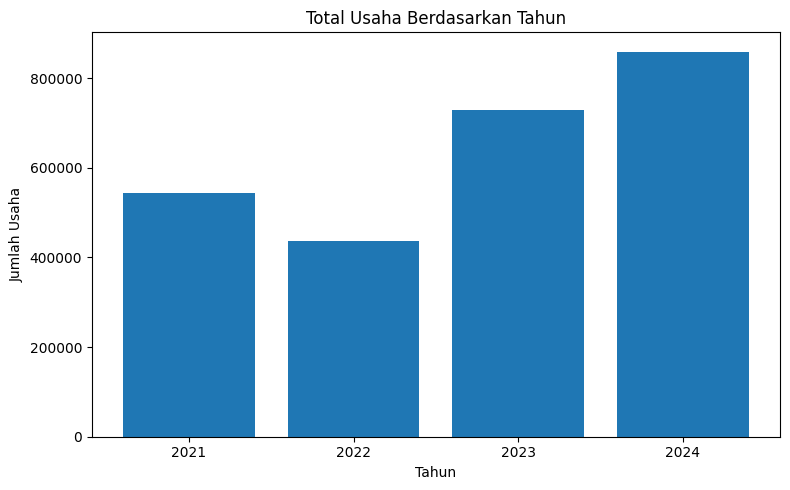

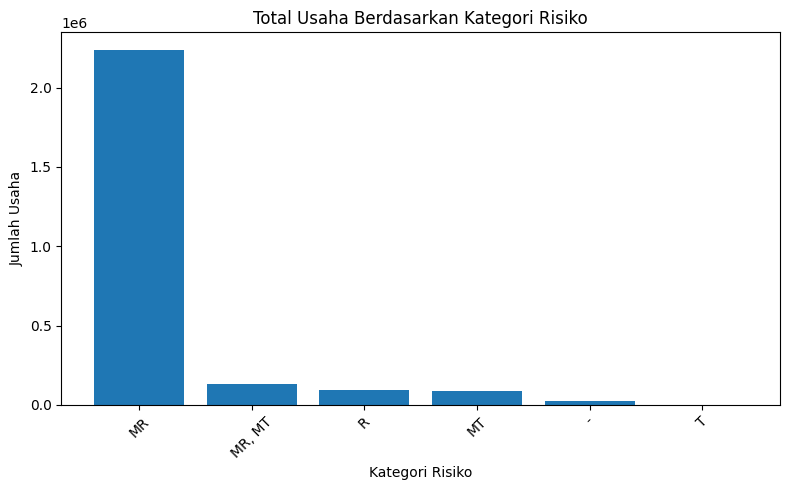

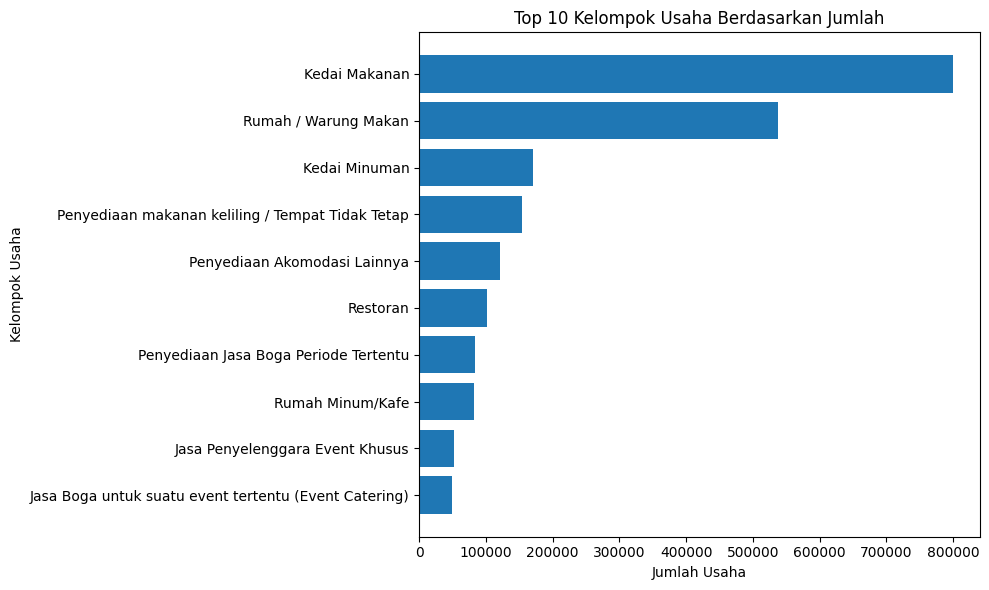

In [37]:
import matplotlib.pyplot as plt

# GRAFIK 1: Total usaha berdasarkan tahun
plt.figure(figsize=(8,5))
plt.bar(
    analisis_tahun["tahun"].astype(str),
    analisis_tahun["total_usaha"]
)
plt.title("Total Usaha Berdasarkan Tahun")
plt.xlabel("Tahun")
plt.ylabel("Jumlah Usaha")
plt.tight_layout()
plt.show()


# GRAFIK 2: Total usaha berdasarkan kategori risiko
plt.figure(figsize=(8,5))
plt.bar(
    analisis_risiko["kategori_risiko"],
    analisis_risiko["total_usaha"]
)
plt.title("Total Usaha Berdasarkan Kategori Risiko")
plt.xlabel("Kategori Risiko")
plt.ylabel("Jumlah Usaha")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# GRAFIK 3: Top 10 kelompok usaha
plt.figure(figsize=(10,6))
plt.barh(
    top_10_usaha["nama_usaha"],
    top_10_usaha["total_usaha"]
)
plt.title("Top 10 Kelompok Usaha Berdasarkan Jumlah")
plt.xlabel("Jumlah Usaha")
plt.ylabel("Kelompok Usaha")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [38]:
import os
import shutil

# Menghubungkan Google Drive jika belum terhubung
from google.colab import drive
drive.mount('/content/drive')

# Folder utama proyek
folder_proyek = "/content/drive/MyDrive/rtm1_2501010203"

# Membuat folder penyimpanan
folder_raw = os.path.join(folder_proyek, "data", "raw")
folder_clean = os.path.join(folder_proyek, "data", "processed")

os.makedirs(folder_raw, exist_ok=True)
os.makedirs(folder_clean, exist_ok=True)

# 1. Menyimpan dataset Excel asli
shutil.copy(
    nama_file,
    os.path.join(folder_raw, "dataset_raw.xlsx")
)

# 2. Menyimpan dataset hasil cleaning
df_clean.to_csv(
    os.path.join(folder_clean, "dataset_clean.csv"),
    index=False
)

# 3. Menyimpan dataset hasil transformation
df_transform.to_csv(
    os.path.join(folder_clean, "dataset_transform.csv"),
    index=False
)

print("=== PENYIMPANAN BERHASIL ===")
print("Dataset raw:", folder_raw)
print("Dataset cleaning:", folder_clean)
print("Dataset transformation:", folder_clean)

Mounted at /content/drive
=== PENYIMPANAN BERHASIL ===
Dataset raw: /content/drive/MyDrive/rtm1_2501010203/data/raw
Dataset cleaning: /content/drive/MyDrive/rtm1_2501010203/data/processed
Dataset transformation: /content/drive/MyDrive/rtm1_2501010203/data/processed


In [39]:
# MENYIMPAN HASIL ANALISIS DAN GRAFIK

import os
import matplotlib.pyplot as plt

# Membuat folder hasil
folder_hasil = os.path.join(
    folder_proyek, "docs", "results"
)

folder_grafik = os.path.join(
    folder_hasil, "grafik"
)

os.makedirs(folder_grafik, exist_ok=True)

# 1. Menyimpan tabel analisis
analisis_tahun.to_csv(
    os.path.join(folder_hasil, "analisis_tahun.csv"),
    index=False
)

analisis_sektor.to_csv(
    os.path.join(folder_hasil, "analisis_sektor.csv"),
    index=False
)

analisis_risiko.to_csv(
    os.path.join(folder_hasil, "analisis_risiko.csv"),
    index=False
)

top_10_usaha.to_csv(
    os.path.join(folder_hasil, "top_10_usaha.csv"),
    index=False
)

# 2. Menyimpan grafik tahun
plt.figure(figsize=(8,5))
plt.bar(
    analisis_tahun["tahun"].astype(str),
    analisis_tahun["total_usaha"]
)
plt.title("Total Usaha Berdasarkan Tahun")
plt.xlabel("Tahun")
plt.ylabel("Jumlah Usaha")
plt.tight_layout()
plt.savefig(
    os.path.join(folder_grafik, "grafik_tahun.png"),
    dpi=300
)
plt.close()

# 3. Menyimpan grafik risiko
plt.figure(figsize=(8,5))
plt.bar(
    analisis_risiko["kategori_risiko"],
    analisis_risiko["total_usaha"]
)
plt.title("Total Usaha Berdasarkan Risiko")
plt.xlabel("Kategori Risiko")
plt.ylabel("Jumlah Usaha")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    os.path.join(folder_grafik, "grafik_risiko.png"),
    dpi=300
)
plt.close()

# 4. Menyimpan grafik Top 10
plt.figure(figsize=(10,6))
plt.barh(
    top_10_usaha["nama_usaha"],
    top_10_usaha["total_usaha"]
)
plt.title("Top 10 Kelompok Usaha")
plt.xlabel("Jumlah Usaha")
plt.ylabel("Kelompok Usaha")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    os.path.join(folder_grafik, "grafik_top10.png"),
    dpi=300
)
plt.close()

print("Seluruh hasil analisis dan grafik berhasil disimpan!")
print("Lokasi:", folder_hasil)

Seluruh hasil analisis dan grafik berhasil disimpan!
Lokasi: /content/drive/MyDrive/rtm1_2501010203/docs/results
